## LeNet-5 CIA Test 1
**Marks:15**

### Instructions

- Correct the errors without completely rewriting the program.
- Execute the corrected notebook successfully.

<>:47: SyntaxWarning: 'str' object is not callable; perhaps you missed a comma?
<>:47: SyntaxWarning: 'str' object is not callable; perhaps you missed a comma?


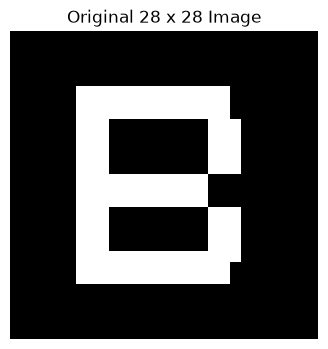

Minimum: 0.0
Maximum: 1.0
After padding: (30, 30)


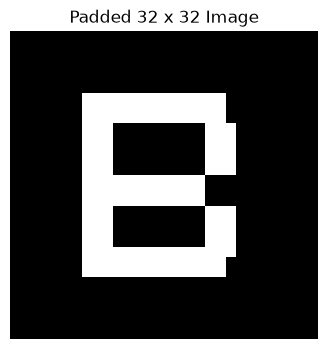

ValueError: cannot reshape array of size 900 into shape (32,32,1)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Create a single 28 x 28 grayscale image
image = np.zeros((28, 28), dtype=np.float32)
image[5:23, 6:9] = 255
image[5:8, 9:20] = 255
image[13:16, 9:18] = 255
image[20:23, 9:20] = 255
image[8:13, 18:21] = 255
image[16:21, 18:21] = 255

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Original 28 x 28 Image")
plt.axis("off")
plt.show()

# Normalize
image = image / 255.0
print("Minimum:", image.min())
print("Maximum:", image.max())

# Pad 28 x 28 to 32 x 32
image = np.pad(image, ((1, 1), (1, 1)), mode="constant", constant_values=0)
print("After padding:", image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Padded 32 x 32 Image")
plt.axis("off")
plt.show()

# Add batch and channel dimensions
image = image.reshape(1, 32, 32, 1)
print("CNN input shape:", image.shape)

# LeNet-5 style model
inputs = tf.keras.Input(shape=(1, 32, 32, 1))

x = tf.keras.layers.Conv2D(6, kernel_size=(5, 5), activation="relu", name="C1")(inputs)
x = tf.keras.layers.AveragePooling2D(pool_size=(3, 3), name="S2")(x)
x = tf.keras.layers.Conv2D(8, kernel_size=(3, 3), activation="tanh", name="C3")(x)
x = tf.keras.layers.AveragePooling2D(pool_size=(2, 2), name="S4")(x)
x = tf.keras.layers.Conv2D(120, kernel_size=(5, 5), activation="tanh", name="C5")(x)
x = tf.keras.layers.Flatten(name="Flatten"(x))
features = tf.keras.layers.Dense(84, activation="tanh", name="F6")(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="Output")(features)

model = tf.keras.Model(inputs=inputs, outputs=outputs)
model.summary()

# Forward pass
prediction = model(image, training=False)
print("Output shape:", prediction.shape)
print("Predicted class:", np.argmax(prediction[0]))

# Extract C1 feature map
c1_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.get_layer("C1").output
)
c1_maps = c1_model(image, training=False)

print("C1 feature map shape:", c1_maps.shape)

plt.figure(figsize=(5, 4))
plt.imshow(c1_maps[0, :, :, 0], cmap="gray")
plt.title("LeNet-5 C1 Feature Map")
plt.axis("off")
plt.show()
